# Wireless Communication Networks and Systems
## LAB 02: Transmission Impairments and Noise
*Python simulation*

---
### General Objectives
At the end of this session, students will be able to:
- Identify main wireless transmission impairments: attenuation, distortion (limited bandwidth), delay/multipath, and noise.
- Simulate each impairment and visualize its impact in time and frequency domains.
- Compute and interpret Signal-to-Noise Ratio (SNR).
- Combine impairments to understand their joint effect and motivate coding/modulation choices.

### Required Tools
- Python 3.x with `numpy` and `matplotlib`. No external DSP library is required.

---
## Starter Notebook Cell (Imports & Helpers)
Paste and run this once at the top of your notebook/script.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Reproducibility
rng = np.random.default_rng(42)

# Global sampling parameters (safe defaults for clear plots)
fs = 10_000  # sampling frequency [Hz]
T = 0.05     # signal duration [s]
N = int(fs * T)  # number of samples
t = np.arange(N) / fs

# ----- Helper functions -----
def rfft_mag(x, fs):
    """One-sided magnitude spectrum."""
    X = np.fft.rfft(x)
    f = np.fft.rfftfreq(len(x), d=1/fs)
    return f, np.abs(X) / len(x)

def add_awgn_snr(x, snr_db, rng=rng):
    """Add AWGN to achieve target SNR (based on average signal power)."""
    p_sig = np.mean(x**2)
    snr_lin = 10**(snr_db / 10)
    p_noise = p_sig / snr_lin
    noise = rng.normal(0, np.sqrt(p_noise), size=len(x))
    return x + noise

def snr_db_calc(x, y):
    """Compute SNR between clean x and noisy y (est. noise = y - x)."""
    noise = y - x
    p_sig = np.mean(x**2)
    p_noise = np.mean(noise**2)
    return 10 * np.log10(p_sig / p_noise + 1e-15)

def moving_average_lpf(x, M):
    """Very simple low-pass filter: length-M moving average (FIR)."""
    h = np.ones(M) / M
    y = np.convolve(x, h, mode='same')
    return y, h

def delay_samples(x, D):
    """Apply a non-causal right shift of D samples with zero padding."""
    if D <= 0:
        return x
    y = np.zeros_like(x)
    y[D:] = x[:-D]
    return y

---
## Step 1 — Reference Signals (Clean)

### 1A. Single-tone sine ("analog" reference)

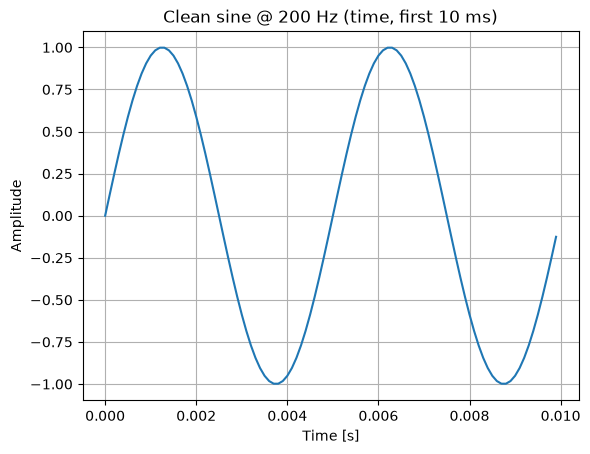

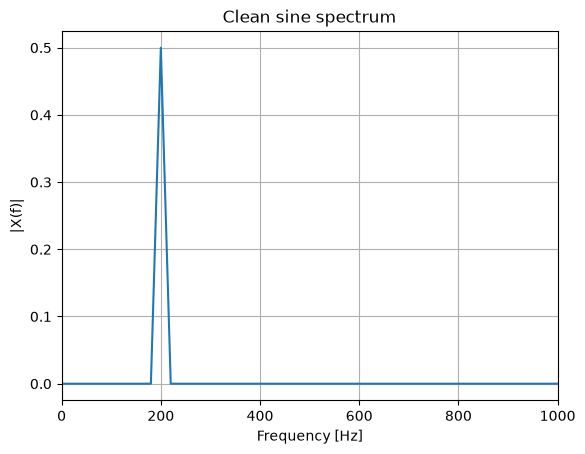

In [3]:
f0 = 200.0  # tone frequency [Hz]
sine = np.sin(2 * np.pi * f0 * t)  # clean reference

# Time view (first 10 ms)
win = int(0.01 * fs)
plt.figure()
plt.plot(t[:win], sine[:win])
plt.title("Clean sine @ 200 Hz (time, first 10 ms)")
plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()

# Frequency view
f, M = rfft_mag(sine, fs)
plt.figure()
plt.plot(f, M)
plt.xlim(0, 1000)
plt.title("Clean sine spectrum")
plt.xlabel("Frequency [Hz]")
plt.ylabel("|X(f)|")
plt.grid(True)
plt.show()

### 1B. Square wave ("digital-like" reference)

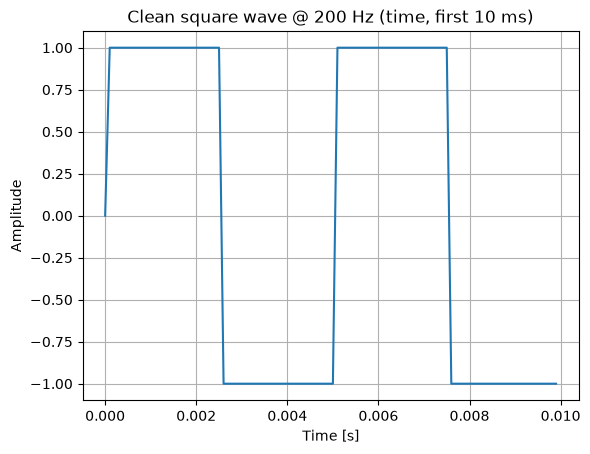

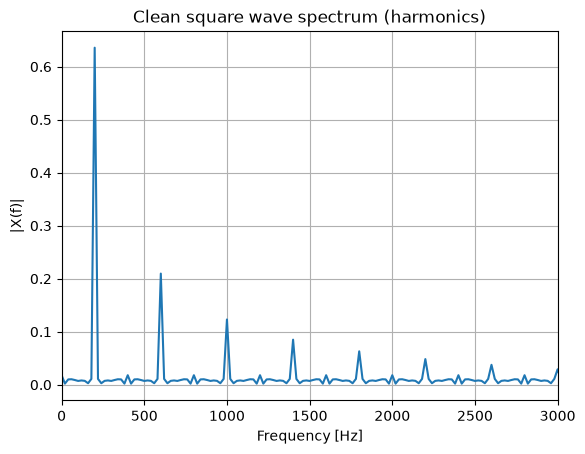

In [4]:
square = np.sign(np.sin(2 * np.pi * f0 * t))

# Time view (first 10 ms)
plt.figure()
plt.plot(t[:win], square[:win])
plt.title("Clean square wave @ 200 Hz (time, first 10 ms)")
plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()

# Frequency view (note odd harmonics)
f, M = rfft_mag(square, fs)
plt.figure()
plt.plot(f, M)
plt.xlim(0, 3000)
plt.title("Clean square wave spectrum (harmonics)")
plt.xlabel("Frequency [Hz]")
plt.ylabel("|X(f)|")
plt.grid(True)
plt.show()

**Observation:** The square wave occupies much more bandwidth due to harmonics (odd multiples of $f_0$).

---
## Step 2 — Attenuation

Scale amplitude to simulate free-space loss or distance.

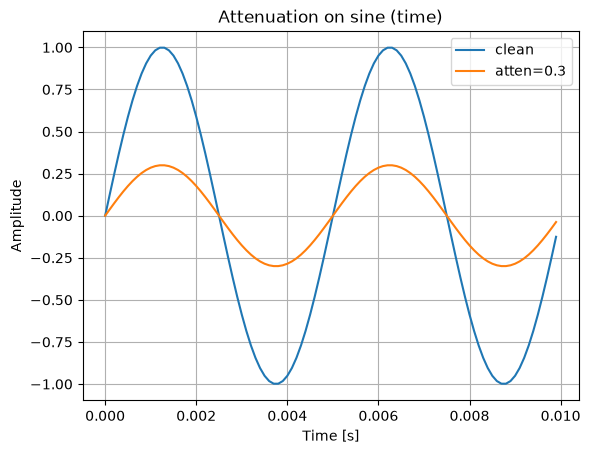

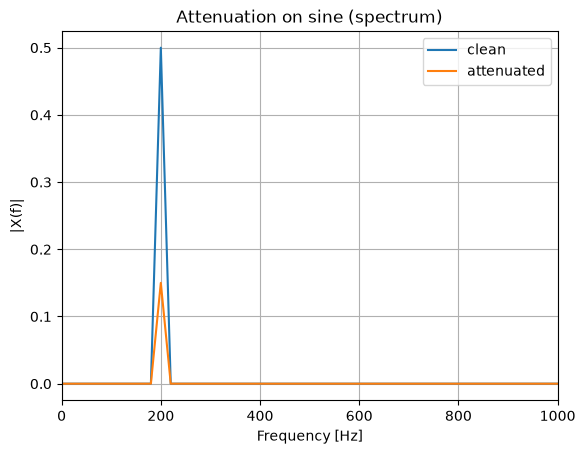

In [5]:
atten = 0.3
sine_att = atten * sine
square_att = atten * square

plt.figure()
plt.plot(t[:win], sine[:win], label="clean")
plt.plot(t[:win], sine_att[:win], label=f"atten={atten}")
plt.title("Attenuation on sine (time)")
plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.grid(True)
plt.legend()
plt.show()

f, M1 = rfft_mag(sine, fs)
_, M2 = rfft_mag(sine_att, fs)
plt.figure()
plt.plot(f, M1, label="clean")
plt.plot(f, M2, label="attenuated")
plt.xlim(0, 1000)
plt.title("Attenuation on sine (spectrum)")
plt.xlabel("Frequency [Hz]")
plt.ylabel("|X(f)|")
plt.grid(True)
plt.legend()
plt.show()

**Key Point:** Attenuation reduces amplitude (and power) without changing spectral shape.

---
## Step 3 — Distortion (Limited Bandwidth)

Apply a simple low-pass filter (moving average) to mimic channel bandwidth limits.

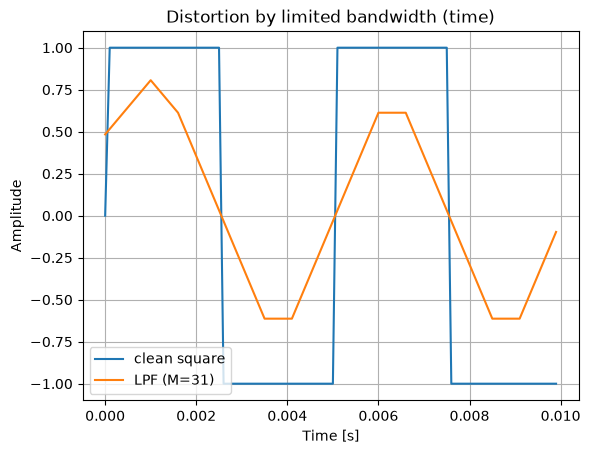

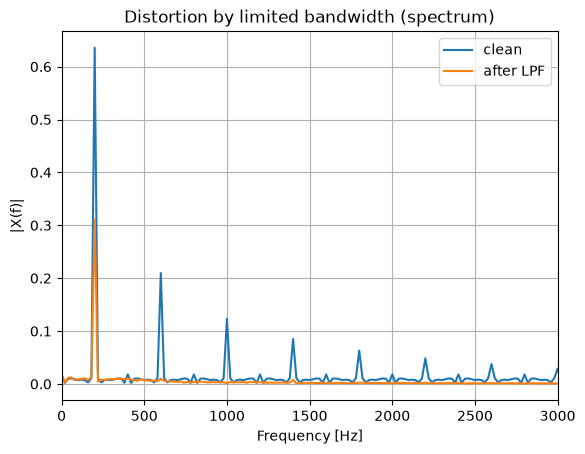

In [6]:
M = 31  # filter length (odd recommended)
square_lp, h = moving_average_lpf(square, M)

# Time view (edges rounded)
plt.figure()
plt.plot(t[:win], square[:win], label="clean square")
plt.plot(t[:win], square_lp[:win], label=f"LPF (M={M})")
plt.title("Distortion by limited bandwidth (time)")
plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.grid(True)
plt.legend()
plt.show()

# Frequency view: high harmonics reduced
f, Mclean = rfft_mag(square, fs)
_, Mlp = rfft_mag(square_lp, fs)
plt.figure()
plt.plot(f, Mclean, label="clean")
plt.plot(f, Mlp, label="after LPF")
plt.xlim(0, 3000)
plt.title("Distortion by limited bandwidth (spectrum)")
plt.xlabel("Frequency [Hz]")
plt.ylabel("|X(f)|")
plt.grid(True)
plt.legend()
plt.show()

**Key Point:** Distortion suppresses higher harmonics, smoothing edges and altering symbol shapes.

---
## Step 4 — Delay and Simple Multipath

Create a delayed echo (weaker copy) and add it to the direct path.

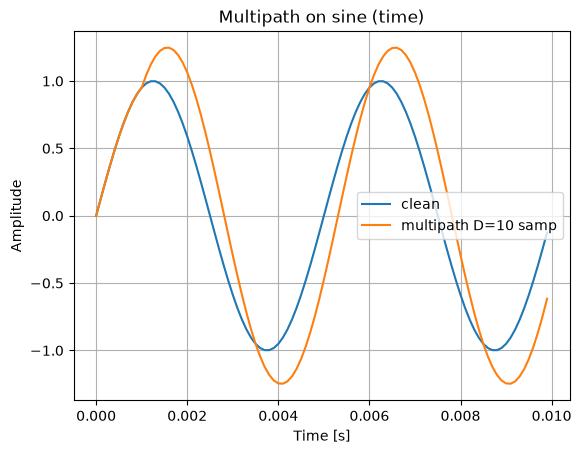

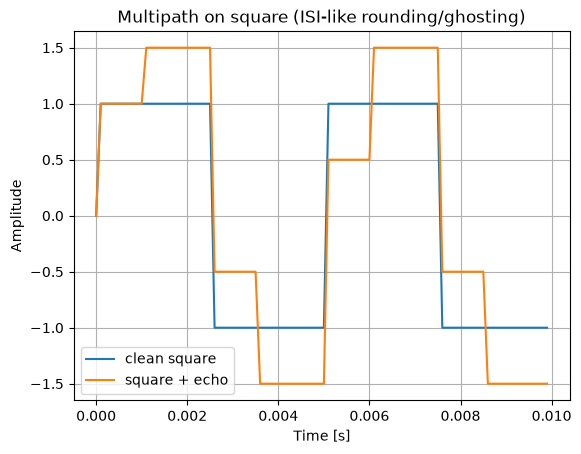

In [7]:
D = int(0.001 * fs)  # delay = 1 ms
a1 = 1.0             # direct path gain
a2 = 0.5             # echo path gain
sine_mp = a1 * sine + a2 * delay_samples(sine, D)

# Time view: visible ripple/echo
plt.figure()
plt.plot(t[:win], sine[:win], label="clean")
plt.plot(t[:win], sine_mp[:win], label=f"multipath D={D} samp")
plt.title("Multipath on sine (time)")
plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.grid(True)
plt.legend()
plt.show()

# Frequency/phase changes exist but are subtle for a pure tone.
# On square wave, multipath can cause inter-symbol interference (ISI):
square_mp = a1 * square + a2 * delay_samples(square, D)
plt.figure()
plt.plot(t[:win], square[:win], label="clean square")
plt.plot(t[:win], square_mp[:win], label="square + echo")
plt.title("Multipath on square (ISI-like rounding/ghosting)")
plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.grid(True)
plt.legend()
plt.show()

**Key Point:** Multipath = delayed copies $\rightarrow$ constructive/destructive interference, ISI.

---
## Step 5 — Additive White Gaussian Noise (AWGN) and SNR

Add noise for target SNR; verify via measured SNR.

Target SNR=6 dB, Measured ~ 6.36 dB


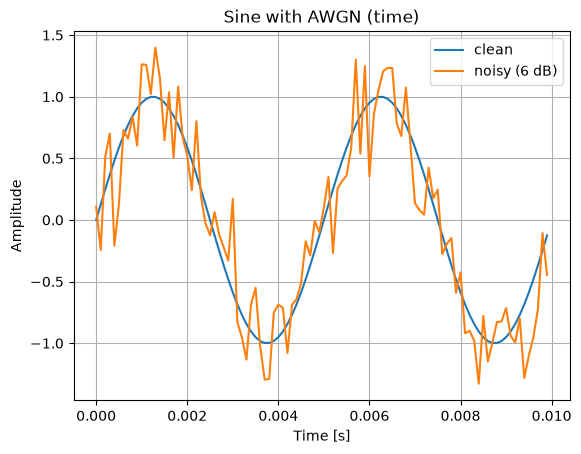

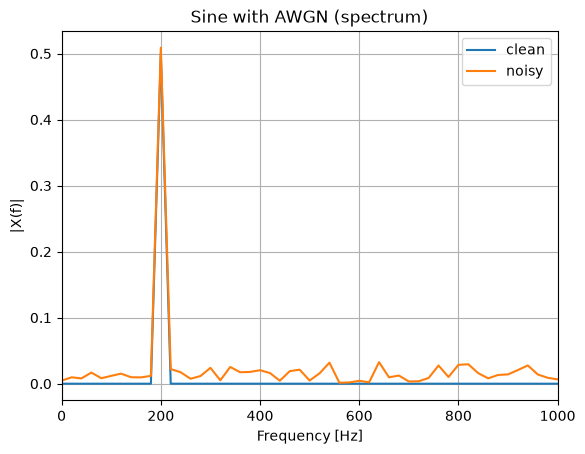

In [8]:
target_snr_db = 6
sine_noisy = add_awgn_snr(sine, target_snr_db)
meas_snr_db = snr_db_calc(sine, sine_noisy)
print(f"Target SNR={target_snr_db} dB, Measured ~ {meas_snr_db:.2f} dB")

# Time view
plt.figure()
plt.plot(t[:win], sine[:win], label="clean")
plt.plot(t[:win], sine_noisy[:win], label=f"noisy ({target_snr_db} dB)")
plt.title("Sine with AWGN (time)")
plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.grid(True)
plt.legend()
plt.show()

# Frequency view
f, Mc = rfft_mag(sine, fs)
_, Mn = rfft_mag(sine_noisy, fs)
plt.figure()
plt.plot(f, Mc, label="clean")
plt.plot(f, Mn, label="noisy")
plt.xlim(0, 1000)
plt.title("Sine with AWGN (spectrum)")
plt.xlabel("Frequency [Hz]")
plt.ylabel("|X(f)|")
plt.grid(True)
plt.legend()
plt.show()

### Mini-exercise
Repeat for $\text{SNR} = 0, 6, 12\text{ dB}$ and comment how the tone peak emerges above the noise floor.

In [9]:
# Mini-exercise: Repeat for SNR = 0, 6, 12 dB



**Observation / Answer:**


---
## Step 6 — Combined Channel (Attenuation + Distortion + Delay + Noise)

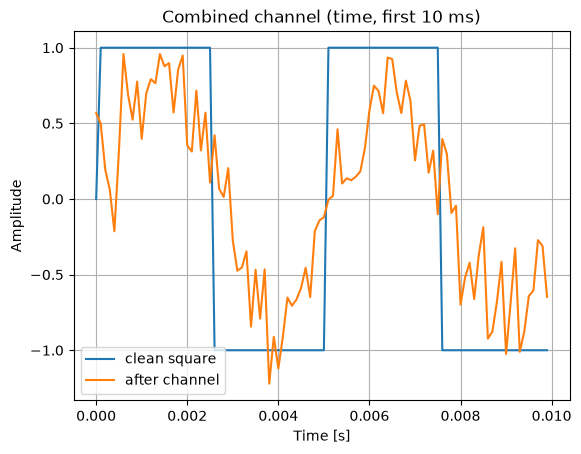

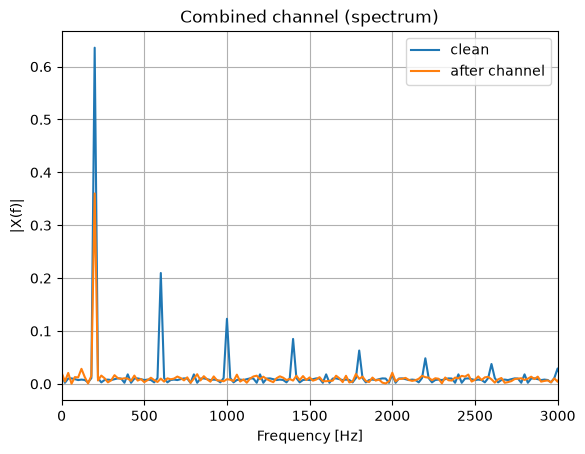

In [10]:
# Start from a "digital-like" square wave to see all effects clearly
x = square.copy()

# 1) attenuation
A = 0.6
y = A * x

# 2) limited bandwidth (distortion)
M = 21
y, h = moving_average_lpf(y, M)

# 3) multipath (echo)
D = int(0.0007 * fs)  # 0.7 ms
a2 = 0.4
y = y + a2 * delay_samples(y, D)

# 4) noise
SNRdB = 8
y_noisy = add_awgn_snr(y, SNRdB)

# Visualize (time)
plt.figure()
plt.plot(t[:win], x[:win], label="clean square")
plt.plot(t[:win], y_noisy[:win], label="after channel")
plt.title("Combined channel (time, first 10 ms)")
plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.grid(True)
plt.legend()
plt.show()

# Visualize (spectrum)
f1, Mx = rfft_mag(x, fs)
f2, My = rfft_mag(y_noisy, fs)
plt.figure()
plt.plot(f1, Mx, label="clean")
plt.plot(f2, My, label="after channel")
plt.xlim(0, 3000)
plt.title("Combined channel (spectrum)")
plt.xlabel("Frequency [Hz]")
plt.ylabel("|X(f)|")
plt.grid(True)
plt.legend()
plt.show()

### Reflection
Which impairment had the largest visual impact on shape? Which mainly reduced power? How would a symbol detector be affected?

**Answer:**


---
## Discussion Questions

### Question 1
Which impairment reduces amplitude without changing spectral shape? Why?

**Answer:**


### Question 2
Why does limited bandwidth distort square waves more than sines?

**Answer:**


### Question 3
How does multipath cause inter-symbol interference (ISI)?

**Answer:**


### Question 4
In the spectrum plots with noise, why is the tone still visible at moderate SNR?

**Answer:**


### Question 5
Give a real-world situation where delay is significant (e.g., GEO satellites).

**Answer:**
